In [84]:
import numpy as np
import json
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

OUTPUT_DIR = Path("robot_wear_dataset")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

JOINT_NAMES = ["shoulder_pitch", "shoulder_roll", "elbow_flex",
               "elbow_rot", "wrist_pitch", "wrist_roll", "gripper"]

wear_starts    = []   # wear state at the START of each episode
wear_increases = []   # how much wear accumulated DURING each episode (our prediction target)
stress_avgs    = []   # avg stress per joint during each episode (our input feature)

for episode_id in range(5000):
    episode_dir = OUTPUT_DIR / f"episode_{episode_id:05d}"
    with open(episode_dir / "metadata.json") as f:
        meta = json.load(f)

    wear_starts.append(meta["wear_start"])
    wear_increases.append(meta["wear_increase"])

    stress = []
    for j in range(7):
        for key in meta["stress_history"]:
            if key.startswith(f"joint_{j}_"):
                stress.append(meta["stress_history"][key]["avg_stress"])
                break
    stress_avgs.append(stress)

wear_starts    = np.array(wear_starts,    dtype=np.float32)   # (5000, 7)
wear_increases = np.array(wear_increases, dtype=np.float32)   # (5000, 7) ← prediction target
stress_avgs    = np.array(stress_avgs,    dtype=np.float32)   # (5000, 7)

print(f"Episodes loaded : {len(wear_starts)}")
print(f"Wear start range: {wear_starts.min():.4f} – {wear_starts.max():.4f}")
print(f"Delta range     : {wear_increases.min():.2e} – {wear_increases.max():.2e}")
print(f"Stress range    : {stress_avgs.min():.1f} – {stress_avgs.max():.1f}")


Device: cpu
Episodes loaded : 5000
Wear start range: 0.0100 – 0.7000
Delta range     : 1.05e-06 – 1.04e-02
Stress range    : 6.5 – 216.4


In [85]:
TRAIN_SIZE  = 4000
SEQ_LENGTH  = 1    # current step only — delta depends on current stress, not history

# Fit normalization stats on training data only
ws_mean = wear_starts[:TRAIN_SIZE].mean(0);  ws_std = wear_starts[:TRAIN_SIZE].std(0) + 1e-8
wi_mean = wear_increases[:TRAIN_SIZE].mean(0); wi_std = wear_increases[:TRAIN_SIZE].std(0) + 1e-8
sf_mean = stress_avgs[:TRAIN_SIZE].mean(0);   sf_std = stress_avgs[:TRAIN_SIZE].std(0) + 1e-8

wear_norm   = (wear_starts    - ws_mean) / ws_std
delta_norm  = (wear_increases - wi_mean) / wi_std
stress_norm = (stress_avgs    - sf_mean) / sf_std

features = np.concatenate([wear_norm, stress_norm], axis=1)   # (5000, 14)

# Input:  [wear_t, stress_t]  — stress_t is directly visible
# Target: delta_t             — caused by stress_t
# The model must learn: stress_t → delta_t
X = features[:, np.newaxis, :]   # (5000, 1, 14) — keep 3D for LSTM compatibility
y = delta_norm                    # (5000, 7)

X_train, X_test = X[:TRAIN_SIZE], X[TRAIN_SIZE:]
y_train, y_test = y[:TRAIN_SIZE], y[TRAIN_SIZE:]

X_train_t = torch.from_numpy(X_train.astype(np.float32)).to(device)
y_train_t = torch.from_numpy(y_train.astype(np.float32)).to(device)
X_test_t  = torch.from_numpy(X_test.astype(np.float32)).to(device)
y_test_t  = torch.from_numpy(y_test.astype(np.float32)).to(device)

print(f"Train: {X_train_t.shape}  |  Test: {X_test_t.shape}")
print(f"Target (normalized delta) range: {y_train.min():.2f} to {y_train.max():.2f}")


Train: torch.Size([4000, 1, 14])  |  Test: torch.Size([1000, 1, 14])
Target (normalized delta) range: -1.09 to 4.85


In [86]:
class BayesianLSTM(nn.Module):
    """Predicts wear-increase deltas from wear+stress history.

    Uncertainty comes from two sources:
      - Aleatoric: the model's own predicted log-std (irreducible noise)
      - Epistemic: variance across MC-Dropout forward passes (model uncertainty)
    """
    def __init__(self, input_dim=14, hidden_dim=128, output_dim=7, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=2,
                            batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc_mean = nn.Sequential(
            nn.Linear(hidden_dim, 64), nn.ELU(),
            nn.Linear(64, output_dim)
        )
        self.fc_logstd = nn.Sequential(
            nn.Linear(hidden_dim, 64), nn.ELU(),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        h = self.dropout(out[:, -1, :])
        return self.fc_mean(h), self.fc_logstd(h)

    def mc_predict(self, x, n_samples=50):
        """Run n_samples stochastic forward passes (dropout kept ON) for uncertainty."""
        self.train()                             # keep dropout active
        with torch.no_grad():
            results = [self(x) for _ in range(n_samples)]
        means   = torch.stack([r[0] for r in results])   # (S, B, 7)
        logstds = torch.stack([r[1] for r in results])   # (S, B, 7)

        mc_mean = means.mean(0)                                              # (B, 7)
        epistemic = means.var(0)                                             # model uncertainty
        aleatoric = torch.exp(2 * logstds).mean(0)                          # data noise
        mc_std    = (epistemic + aleatoric).sqrt()                           # total uncertainty
        return mc_mean, mc_std


model     = BayesianLSTM().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

n_params = sum(p.numel() for p in model.parameters())
print(f"BayesianLSTM ready  |  {n_params:,} parameters")


BayesianLSTM ready  |  223,246 parameters


In [87]:
def gaussian_nll(mean, logstd, target):
    return (0.5 * ((target - mean)**2 / torch.exp(2*logstd) + 2*logstd)).mean()

BATCH_SIZE = 64
NUM_EPOCHS = 100

loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                    batch_size=BATCH_SIZE, shuffle=True)
train_losses = []

for epoch in range(NUM_EPOCHS):
    model.train()
    epoch_loss = 0.0
    for Xb, yb in loader:
        mean, logstd = model(Xb)
        loss = gaussian_nll(mean, logstd, yb)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # prevent exploding gradients
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    avg = epoch_loss / len(loader)
    train_losses.append(avg)
    if (epoch + 1) % 20 == 0:
        lr = scheduler.get_last_lr()[0]
        print(f"Epoch {epoch+1:3d}/{NUM_EPOCHS}  loss={avg:.4f}  lr={lr:.2e}")

print("✓ Training complete")


Epoch  20/100  loss=-2.6223  lr=9.05e-04
Epoch  40/100  loss=-2.8139  lr=6.55e-04
Epoch  60/100  loss=-2.8544  lr=3.45e-04
Epoch  80/100  loss=-2.9502  lr=9.55e-05
Epoch 100/100  loss=-2.9866  lr=0.00e+00
✓ Training complete


In [88]:
# MC Dropout evaluation — 50 stochastic passes
mc_mean, mc_std = model.mc_predict(X_test_t, n_samples=50)
mc_mean_np = mc_mean.cpu().numpy()
mc_std_np  = mc_std.cpu().numpy()

mae = np.abs(mc_mean_np - y_test).mean()
mse = ((mc_mean_np - y_test)**2).mean()

print(f"Delta prediction  —  MAE: {mae:.4f}  |  MSE: {mse:.4f}  (normalized space)")
print()
print(f"{'Joint':22} MAE      Uncertainty (±1σ)")
print("-" * 50)
for j, name in enumerate(JOINT_NAMES):
    j_mae = np.abs(mc_mean_np[:, j] - y_test[:, j]).mean()
    j_unc = mc_std_np[:, j].mean()
    print(f"  {name:20} {j_mae:.4f}   ±{j_unc:.4f}")

# Uncertainty calibration check: a well-calibrated model has MAE ≈ uncertainty
print()
print("Calibration check: MAE should be close to uncertainty (within 2x)")
ratio = mae / mc_std_np.mean()
if 0.5 < ratio < 2.0:
    print(f"  ✓ Well calibrated  (MAE/σ = {ratio:.2f})")
else:
    print(f"  ⚠ Miscalibrated   (MAE/σ = {ratio:.2f})")


Delta prediction  —  MAE: 0.0600  |  MSE: 0.1096  (normalized space)

Joint                  MAE      Uncertainty (±1σ)
--------------------------------------------------
  shoulder_pitch       0.0286   ±0.0944
  shoulder_roll        0.0290   ±0.0943
  elbow_flex           0.0291   ±0.0945
  elbow_rot            0.0288   ±0.0945
  wrist_pitch          0.0294   ±0.0945
  wrist_roll           0.0290   ±0.0946
  gripper              0.2459   ±0.4519

Calibration check: MAE should be close to uncertainty (within 2x)
  ⚠ Miscalibrated   (MAE/σ = 0.41)


Running world model imagination: 1000 steps × 30 MC samples ...


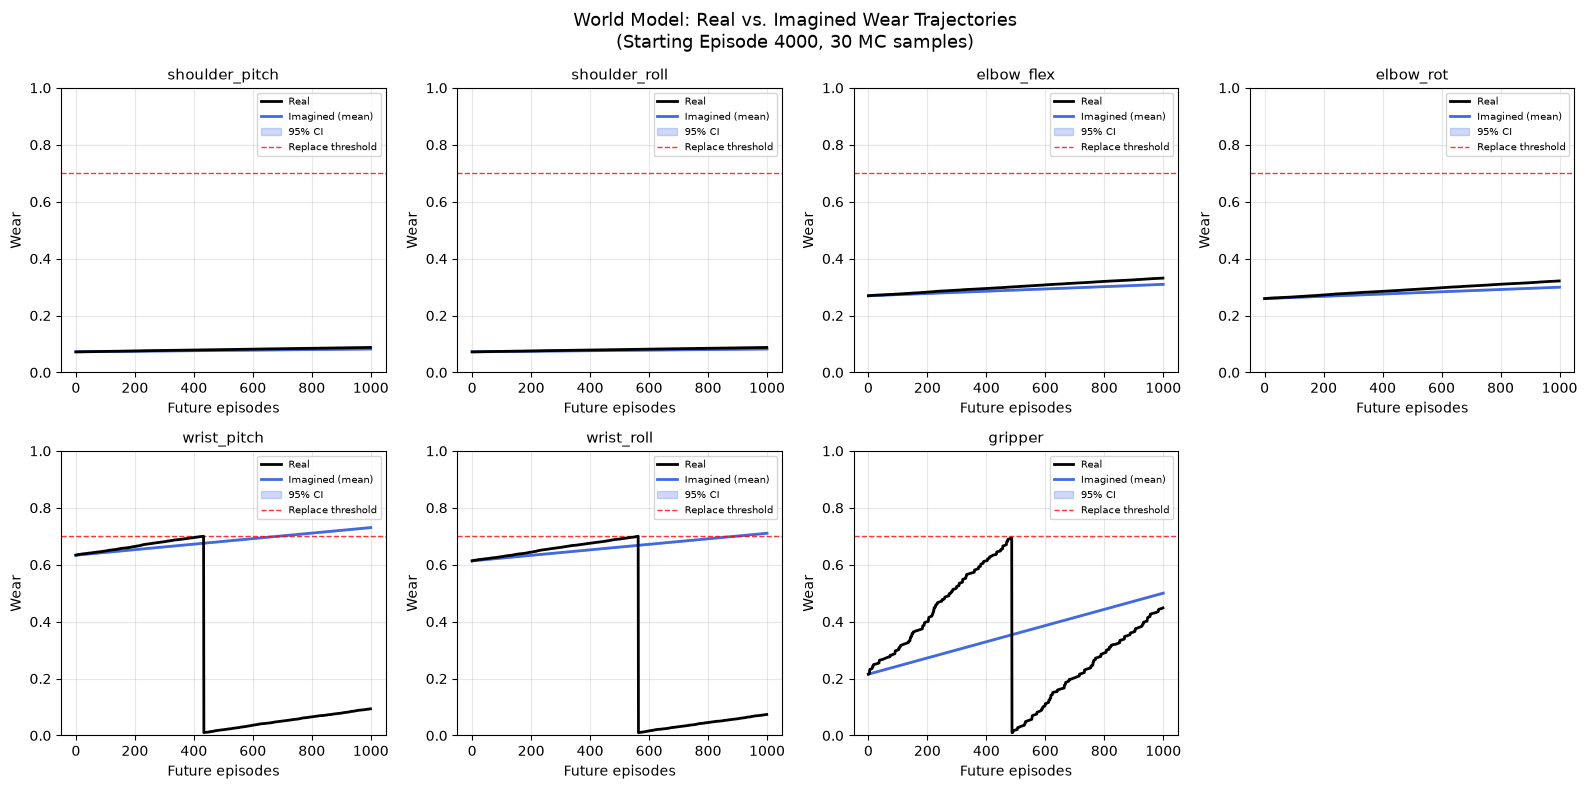

Saved → world_model_rollout.png


In [89]:
def rollout(seed_wear, n_steps=1000, n_samples=30, stress_multiplier=1.0, deterministic=False):
    """
    World-model imagination from a starting wear state.

    seed_wear       : (7,) raw wear values at the start episode
    n_steps         : future episodes to simulate
    n_samples       : MC-Dropout passes for uncertainty
    stress_multiplier: scale all stress inputs (>1 = heavier, <1 = lighter)
    deterministic   : True = use predicted mean only (for scenario comparison)
                      False = sample from distribution (for uncertainty bands)

    Returns mean_traj, std_traj in raw wear units, shape (n_steps+1, 7).
    """
    # Use average stress from the seed region, scaled by multiplier
    seed_ep = START_EP
    raw_stress_seed = stress_avgs[seed_ep - 10 : seed_ep].mean(0)   # (7,) avg recent stress
    raw_stress = raw_stress_seed * stress_multiplier                  # scaled

    trajectories = []

    for _ in range(n_samples):
        wear = seed_wear.copy()
        traj = [wear.copy()]

        for _ in range(n_steps):
            wear_norm_t   = (wear     - ws_mean) / ws_std       # (7,)
            stress_norm_t = (raw_stress - sf_mean) / sf_std     # (7,)
            feat = np.concatenate([wear_norm_t, stress_norm_t]) # (14,)

            x = torch.FloatTensor(feat[np.newaxis, np.newaxis, :]).to(device)  # (1, 1, 14)
            model.train()
            with torch.no_grad():
                d_mean, d_logstd = model(x)
                if deterministic:
                    d_sample = d_mean
                else:
                    d_sample = d_mean + torch.randn_like(d_mean) * torch.exp(d_logstd)

            delta_raw = d_sample.cpu().numpy()[0] * wi_std + wi_mean
            wear = np.clip(wear + delta_raw, 0.0, 1.0)
            traj.append(wear.copy())

        trajectories.append(np.array(traj))

    trajectories = np.array(trajectories)   # (n_samples, n_steps+1, 7)
    return trajectories.mean(0), trajectories.std(0)


# --- Run rollout from episode 4000 ---
START_EP  = TRAIN_SIZE
N_STEPS   = 1000
N_SAMPLES = 30

seed_wear = wear_starts[START_EP].copy()

print(f"Running world model imagination: {N_STEPS} steps × {N_SAMPLES} MC samples ...")
mean_traj, std_traj = rollout(seed_wear, n_steps=N_STEPS, n_samples=N_SAMPLES, deterministic=False)

real_wear = wear_starts[START_EP : START_EP + N_STEPS + 1]
real_len  = len(real_wear)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
steps = np.arange(mean_traj.shape[0])

for j in range(7):
    ax = axes[j]
    ax.plot(steps[:real_len], real_wear[:, j],
            color='black', lw=2, label='Real', zorder=3)
    ax.plot(steps, mean_traj[:, j],
            color='royalblue', lw=2, label='Imagined (mean)', zorder=2)
    ax.fill_between(steps,
                    mean_traj[:, j] - 2*std_traj[:, j],
                    mean_traj[:, j] + 2*std_traj[:, j],
                    alpha=0.25, color='royalblue', label='95% CI', zorder=1)
    ax.axhline(0.7, color='red', ls='--', lw=1, alpha=0.8, label='Replace threshold')
    ax.set_title(JOINT_NAMES[j], fontsize=11)
    ax.set_xlabel("Future episodes")
    ax.set_ylabel("Wear")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

axes[-1].axis('off')
plt.suptitle(
    f"World Model: Real vs. Imagined Wear Trajectories\n(Starting Episode {START_EP}, {N_SAMPLES} MC samples)",
    fontsize=13
)
plt.tight_layout()
plt.savefig("world_model_rollout.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → world_model_rollout.png")


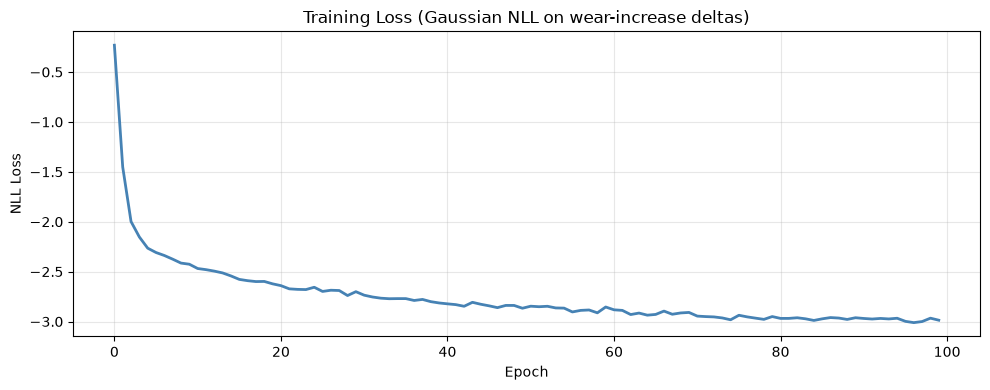

In [90]:
plt.figure(figsize=(10, 4))
plt.plot(train_losses, lw=2, color='steelblue')
plt.xlabel("Epoch")
plt.ylabel("NLL Loss")
plt.title("Training Loss (Gaussian NLL on wear-increase deltas)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [91]:
THRESHOLD = 0.7
N_LONG    = 2000
N_MC_LONG = 50

print(f"Running long-horizon imagination ({N_LONG} steps × {N_MC_LONG} samples) ...")
mean_long, std_long = rollout(seed_wear, n_steps=N_LONG, n_samples=N_MC_LONG, deterministic=False)

print("\n" + "=" * 68)
print(f"MAINTENANCE SCHEDULE  —  Based on world-model imagination")
print(f"(starting from Episode {START_EP})")
print("=" * 68)

timeline = {}

for j, name in enumerate(JOINT_NAMES):
    wear_now = seed_wear[j]
    crossings = np.where(mean_long[:, j] >= THRESHOLD)[0]

    if wear_now >= THRESHOLD:
        status = "🔴 REPLACE NOW"
        abs_ep, abs_lo, abs_hi = START_EP, START_EP, START_EP
    elif len(crossings) > 0:
        fail_ep = crossings[0]
        lo_cross = np.where((mean_long[:, j] - std_long[:, j]) >= THRESHOLD)[0]
        hi_cross = np.where((mean_long[:, j] + std_long[:, j]) >= THRESHOLD)[0]
        ep_lo = lo_cross[0] if len(lo_cross) > 0 else fail_ep
        ep_hi = hi_cross[0] if len(hi_cross) > 0 else min(fail_ep + 300, N_LONG)
        abs_ep  = START_EP + fail_ep
        abs_lo  = START_EP + ep_lo
        abs_hi  = START_EP + ep_hi
        status  = ("🟠 CRITICAL" if fail_ep < 400 else
                   "🟡 WARNING"  if fail_ep < 1000 else "🟢 OK")
    else:
        abs_ep = abs_lo = abs_hi = START_EP + N_LONG + 1
        status = "🟢 OK (>2000 ep)"

    timeline[name] = (abs_ep, abs_lo, abs_hi, wear_now, status)

    if wear_now < THRESHOLD and len(crossings) > 0:
        print(f"\n{name:22} {status}")
        print(f"  Current wear  : {wear_now:.3f}")
        print(f"  Replace by    : Episode {abs_ep}  (range: {abs_lo}–{abs_hi})")
    else:
        print(f"\n{name:22} {status}  (wear={wear_now:.3f})")

print("\n" + "=" * 68)
print("PRIORITY REPLACEMENT TIMELINE")
print("=" * 68)
for name, (ep, lo, hi, wear, status) in sorted(timeline.items(), key=lambda x: x[1][0]):
    ep_str = f"Ep {ep:5d}  [{lo}–{hi}]" if ep < START_EP + N_LONG else ">2000 episodes away"
    print(f"  {name:22} {ep_str}   {status}")


Running long-horizon imagination (2000 steps × 50 samples) ...

MAINTENANCE SCHEDULE  —  Based on world-model imagination
(starting from Episode 4000)

shoulder_pitch         🟢 OK (>2000 ep)  (wear=0.072)

shoulder_roll          🟢 OK (>2000 ep)  (wear=0.072)

elbow_flex             🟢 OK (>2000 ep)  (wear=0.269)

elbow_rot              🟢 OK (>2000 ep)  (wear=0.259)

wrist_pitch            🟡 WARNING
  Current wear  : 0.634
  Replace by    : Episode 4685  (range: 4686–4684)

wrist_roll             🟡 WARNING
  Current wear  : 0.614
  Replace by    : Episode 4891  (range: 4892–4890)

gripper                🟢 OK
  Current wear  : 0.216
  Replace by    : Episode 5702  (range: 5703–5701)

PRIORITY REPLACEMENT TIMELINE
  wrist_pitch            Ep  4685  [4686–4684]   🟡 WARNING
  wrist_roll             Ep  4891  [4892–4890]   🟡 WARNING
  gripper                Ep  5702  [5703–5701]   🟢 OK
  shoulder_pitch         >2000 episodes away   🟢 OK (>2000 ep)
  shoulder_roll          >2000 episodes away 

Scenario start — ep 1500  |  gripper wear: 0.038
  Simulating: Light duty (stress ×0.6) ...
  Simulating: Normal (stress ×1.0) ...
  Simulating: Heavy duty (stress ×1.5) ...


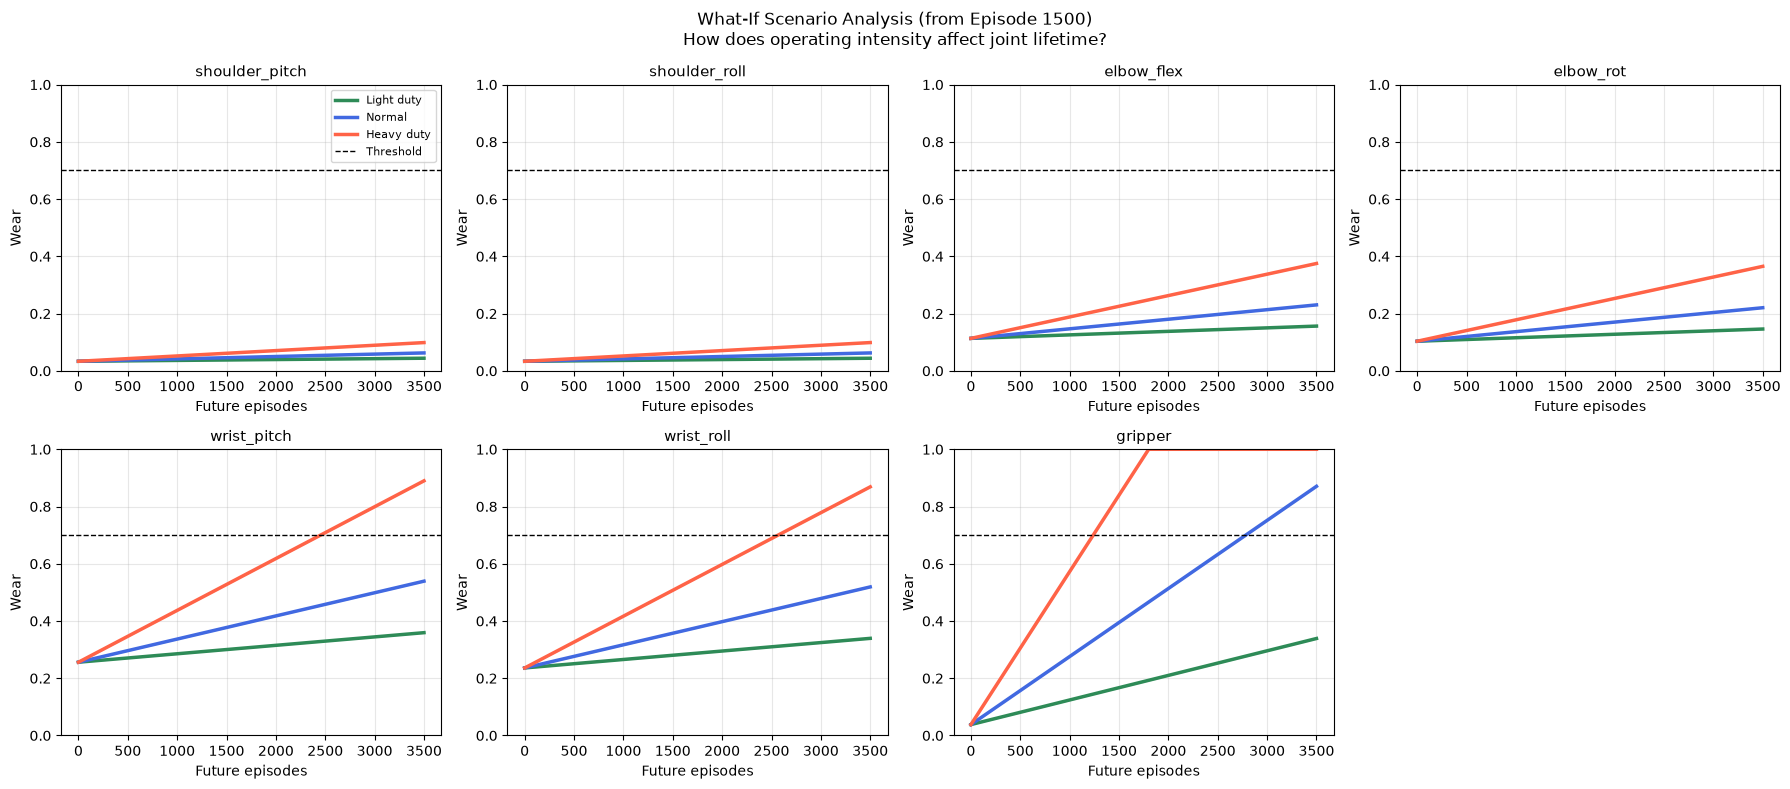

Saved → scenario_analysis.png

Lifetime comparison (episodes from ep 1500 until threshold):
Joint                     Light   Normal    Heavy  Heavy vs Normal
------------------------------------------------------------------------
  shoulder_pitch          >3500     >3500     >3500  no difference
  shoulder_roll           >3500     >3500     >3500  no difference
  elbow_flex              >3500     >3500     >3500  no difference
  elbow_rot               >3500     >3500     >3500  no difference
  wrist_pitch             >3500     >3500      2452  fails 1049 ep sooner ✓
  wrist_roll              >3500     >3500      2566  fails 935 ep sooner ✓
  gripper                 >3500      2784      1239  fails 1545 ep sooner ✓


In [93]:
SCENARIOS = [
    (0.6, "Light duty",  "seagreen"),
    (1.0, "Normal",      "royalblue"),
    (1.5, "Heavy duty",  "tomato"),
]

SCENARIO_START = 1500
S_STEPS   = 3500    # extended window so all three scenarios cross threshold
S_SAMPLES = 30

scenario_seed_wear = wear_starts[SCENARIO_START].copy()
print(f"Scenario start — ep {SCENARIO_START}  |  gripper wear: {scenario_seed_wear[6]:.3f}")

_orig_start = START_EP
START_EP = SCENARIO_START

scenario_results = {}
for mult, label, color in SCENARIOS:
    print(f"  Simulating: {label} (stress ×{mult}) ...")
    m, s = rollout(scenario_seed_wear, n_steps=S_STEPS, n_samples=S_SAMPLES,
                   stress_multiplier=mult, deterministic=True)
    scenario_results[label] = (m, s, color)

START_EP = _orig_start

steps_s = np.arange(S_STEPS + 1)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for j in range(7):
    ax = axes[j]
    for label, (m, s, color) in scenario_results.items():
        ax.plot(steps_s, m[:, j], color=color, lw=2.5, label=label)
        ax.fill_between(steps_s, m[:, j] - s[:, j], m[:, j] + s[:, j],
                        alpha=0.12, color=color)
    ax.axhline(THRESHOLD, color='black', ls='--', lw=1, label='Threshold')
    ax.set_title(JOINT_NAMES[j], fontsize=11)
    ax.set_xlabel("Future episodes")
    ax.set_ylabel("Wear")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    if j == 0:
        ax.legend(fontsize=8)

axes[-1].axis('off')
plt.suptitle(
    f"What-If Scenario Analysis (from Episode {SCENARIO_START})\n"
    "How does operating intensity affect joint lifetime?",
    fontsize=12
)
plt.tight_layout()
plt.savefig("scenario_analysis.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → scenario_analysis.png")

print(f"\nLifetime comparison (episodes from ep {SCENARIO_START} until threshold):")
print(f"{'Joint':22} {'Light':>8} {'Normal':>8} {'Heavy':>8}  Heavy vs Normal")
print("-" * 72)
for j, name in enumerate(JOINT_NAMES):
    lifetimes = {}
    for label, (m, s, _) in scenario_results.items():
        cross = np.where(m[:, j] >= THRESHOLD)[0]
        lifetimes[label] = cross[0] if len(cross) > 0 else S_STEPS + 1
    lt = lifetimes["Light duty"]; nm = lifetimes["Normal"]; hv = lifetimes["Heavy duty"]
    lt_s = str(lt) if lt <= S_STEPS else f">{S_STEPS}"
    nm_s = str(nm) if nm <= S_STEPS else f">{S_STEPS}"
    hv_s = str(hv) if hv <= S_STEPS else f">{S_STEPS}"
    if hv < nm:
        diff = f"fails {nm-hv} ep sooner ✓"
    elif hv > nm:
        diff = f"fails {hv-nm} ep later (?)"
    else:
        diff = "no difference"
    print(f"  {name:20} {lt_s:>8}  {nm_s:>8}  {hv_s:>8}  {diff}")
